# RetainIQ 02 - EDA, hypothesis tests, clustering
DESCRIPTIVE only - real 10,000 rows, no synthetic data. Language: *associated with*, never *causes*.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, '../src')
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 200)

In [2]:
import eda
eda.main()

Overall churn 15.8% | churned balance share 6.6%
                           customers  churn_rate
complaint_count_last_year                       
0.0                             7001    0.131267
1.0                             2475    0.200808
2.0                              457    0.310722
3.0                               59    0.271186
4.0                                7    0.428571
5.0                                1    1.000000
                          feature       auc           direction
2                    num_products  0.732528   lower->more churn
5        digital_engagement_score  0.658788   lower->more churn
10      last_transaction_days_ago  0.644778  higher->more churn
12                   segment_rank  0.633935   lower->more churn
3                    tenure_years  0.633550   lower->more churn
0             avg_monthly_balance  0.631640   lower->more churn
1                  monthly_income  0.629545   lower->more churn
9                       nps_score  0.622771   l

                                        persona  size  churn_rate  median_balance  num_products  complaints_grp  last_transaction_days_ago  share_churned_balance
cluster                                                                                                                                                          
0               Disgruntled Unhappy Mass Market  1632    0.249387          5926.0      2.061887        1.305760                  23.831495               0.178853
1                           Digital Mass Market  2922    0.105065          4929.5      1.979808        0.084531                  16.705681               0.114162
2                         Multi-Product Wealthy  1919    0.040125         79189.0      3.531527        0.314226                  24.053153               0.440577
3                           Veteran Mass Market   925    0.050811          5552.0      2.475676        0.231351                  24.120000               0.021034
4        Low-Digital Branch-

{
  "overall": {
    "customers": 10000,
    "churners": 1578,
    "churn_rate": 0.1578,
    "churn_rate_ci": [
      0.15078645301943353,
      0.16507635546545754
    ],
    "churned_balance_share": 0.06561021073252264,
    "total_balance": 342453785.0,
    "churned_balance": 22468465.0,
    "accuracy_of_predict_nobody": 0.8422000000000001,
    "churned_balance_share_winsor99": 0.06885534201597289
  },
  "volume_vs_value": {
    "mass_market_share_of_churners": 0.7306717363751585,
    "mass_market_share_of_churned_balance": 0.18824850740804946,
    "top_quintile_balance_share_of_churners": 0.0741444866920152,
    "top_quintile_balance_share_of_churned_balance": 0.5591626308250252,
    "n_high_balance_leavers": 117,
    "median_balance_churned": 4065.5,
    "median_balance_stayed": 8417.5
  }
}

PASS: all EDA on real rows only (n=10000)


In [3]:
E = json.load(open('../outputs/eda_results.json'))
pd.DataFrame(E['bh_adjusted_p'], index=['BH-adjusted p']).T

,BH-adjusted p
MW_avg_monthly_balance,1.142412e-61
MW_monthly_income,8.401266e-60
MW_num_products,4.060517e-206
MW_tenure_years,2.597831e-63
MW_age,2.919225e-05
MW_digital_engagement_score,1.134660e-88
MW_branch_visits_last_year,7.754320e-18
MW_complaint_count_last_year,3.684633e-32
MW_credit_score,1.396640e-24
MW_nps_score,6.675865e-54


In [4]:
pd.read_csv('../outputs/univariate_auc.csv')

,feature,auc,direction,median_churned,median_stayed,rank_biserial,mw_p
0,num_products,0.732528,lower->more churn,1.0,2.0,-0.465056,4.200535e-207
1,digital_engagement_score,0.658788,lower->more churn,45.6,56.4,-0.317576,1.956310e-89
2,last_transaction_days_ago,0.644778,higher->more churn,29.0,16.0,0.289557,1.046021e-74
3,segment_rank,0.633935,lower->more churn,0.0,1.0,-0.267871,3.884194e-77
4,tenure_years,0.633550,lower->more churn,2.3,4.1,-0.267100,8.062233e-64
5,avg_monthly_balance,0.631640,lower->more churn,4065.5,8417.5,-0.263279,4.727222e-62
6,monthly_income,0.629545,lower->more churn,3859.0,4822.5,-0.259090,3.766085e-60
7,nps_score,0.622771,lower->more churn,17.0,28.0,-0.245543,3.222831e-54
8,relationship_manager_assigned,0.582458,lower->more churn,0.0,0.0,-0.164916,7.366466e-50
9,credit_score,0.581141,lower->more churn,746.0,767.0,-0.162281,8.668799e-25


In [5]:
json.dumps(E['hypotheses']['H7_rm_confounding'], indent=1)[:2000]

'{\n "rm_share_by_segment": {\n  "Affluent": 0.814,\n  "Mass Affluent": 0.057,\n  "Mass Market": 0.057,\n  "Private Banking": 0.816\n },\n "median_balance_rm": 61101.0,\n "median_balance_no_rm": 4922.0,\n "churn_by_segment_rm": {\n  "Mass Market": {\n   "no_rm": 0.2244039270687237,\n   "rm": 0.10855263157894737,\n   "n_no_rm": 4991,\n   "n_rm": 304\n  },\n  "Mass Affluent": {\n   "no_rm": 0.12267080745341614,\n   "rm": 0.07006369426751592,\n   "n_no_rm": 2576,\n   "n_rm": 157\n  },\n  "Affluent": {\n   "no_rm": 0.10144927536231885,\n   "rm": 0.041425020712510356,\n   "n_no_rm": 276,\n   "n_rm": 1207\n  },\n  "Private Banking": {\n   "no_rm": 0.07777777777777778,\n   "rm": 0.03258145363408521,\n   "n_no_rm": 90,\n   "n_rm": 399\n  }\n },\n "crude_or": [\n  0.2398181162335775,\n  0.1958266831686413,\n  0.29369199305843874,\n  2.2220892074235572e-43\n ],\n "adjusted_or": [\n  0.38468711805798006,\n  0.2954066280552536,\n  0.5009507734270436,\n  1.3377144857927012e-12\n ],\n "supported": t

In [6]:
pd.read_csv('../outputs/cluster_profiles.csv')

,cluster,avg_monthly_balance,segment_rank,num_products,digital_engagement_score,branch_visits_last_year,complaints_grp,tenure_years,last_transaction_days_ago,nps_score,relationship_manager_assigned,median_balance,size,churn_rate,share_churned_balance,persona,play
0,0,12372.115196,0.462623,2.061887,56.409007,3.505515,1.305760,4.464338,23.831495,5.890319,0.045956,5926.0,1632,0.249387,0.178853,Disgruntled Unhappy Mass Market,Complaint recovery: 48-hour resolution SLA + p...
1,1,10343.599932,0.377139,1.979808,65.534189,2.485284,0.084531,3.808419,16.705681,33.746407,0.039357,4929.5,2922,0.105065,0.114162,Digital Mass Market,Monitor; light-touch loyalty
2,2,135133.636269,2.196978,3.531527,59.160969,3.502866,0.314226,5.157947,24.053153,32.489838,0.869203,79189.0,1919,0.040125,0.440577,Multi-Product Wealthy,"P2 nurture & deepen: protect relationship, wea..."
3,3,12690.497297,0.455135,2.475676,55.196108,3.527568,0.231351,17.220324,24.120000,26.572973,0.075676,5552.0,925,0.050811,0.021034,Veteran Mass Market,Monitor; light-touch loyalty
4,4,8062.388932,0.258263,1.700999,37.787663,5.407763,0.151806,3.989316,38.870100,23.818985,0.053420,3789.0,2602,0.284397,0.245374,Low-Digital Branch-Reliant Mass Market,P3 low-cost automation: second-product bundle ...


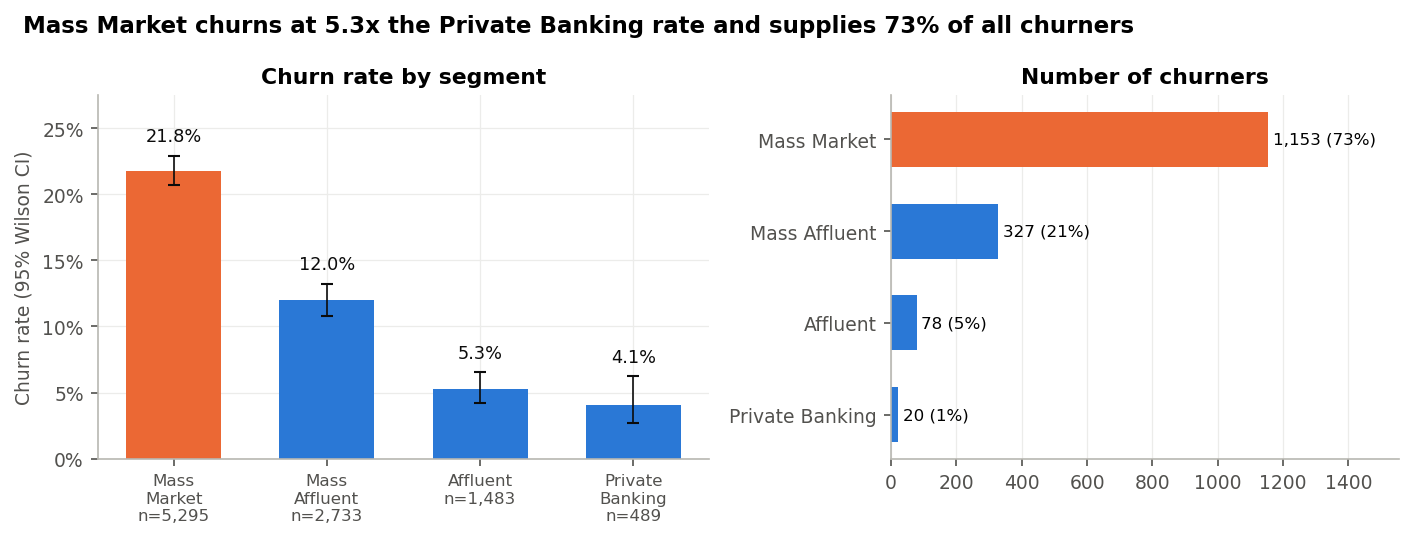

In [7]:
display(Image('../outputs/figures/01_churn_by_segment.png'))

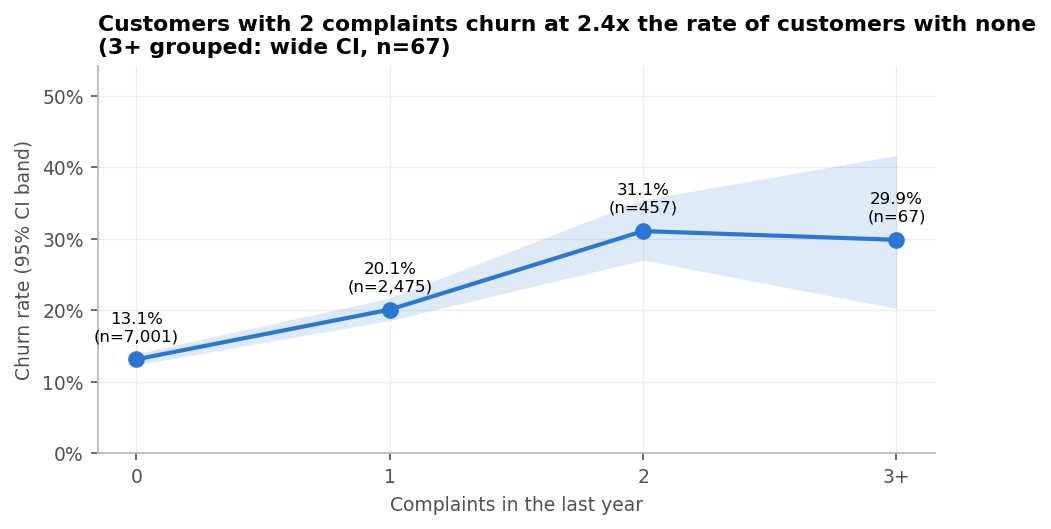

In [8]:
display(Image('../outputs/figures/02_complaints_dose_response.png'))

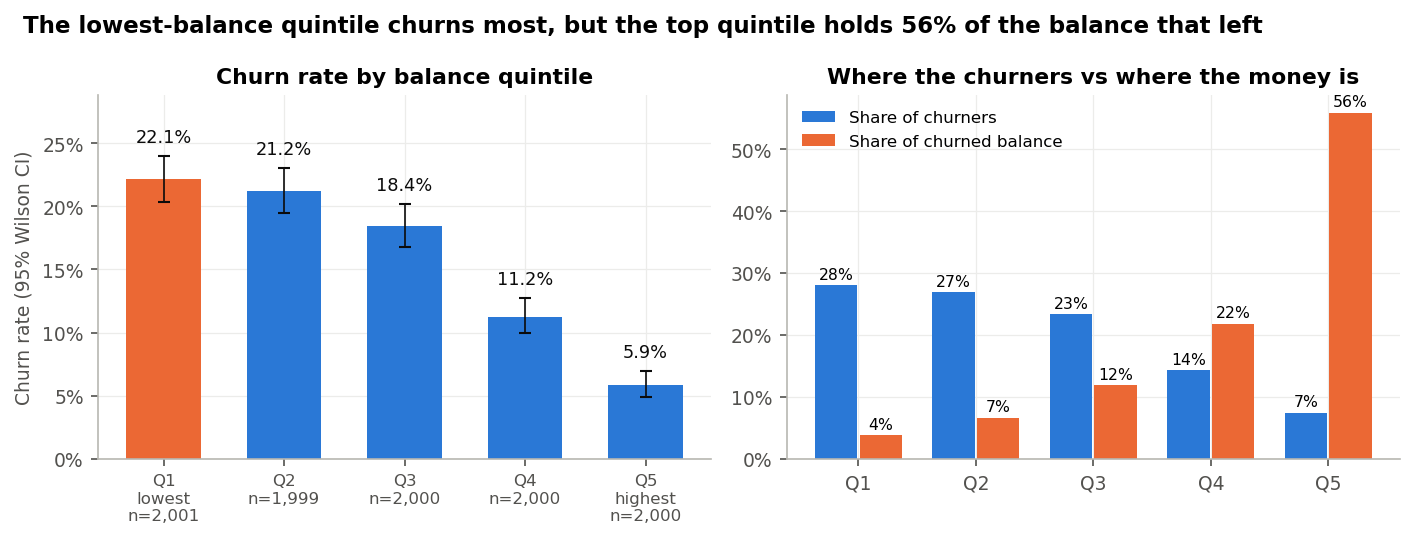

In [9]:
display(Image('../outputs/figures/03_balance_quintile_rate_vs_value.png'))

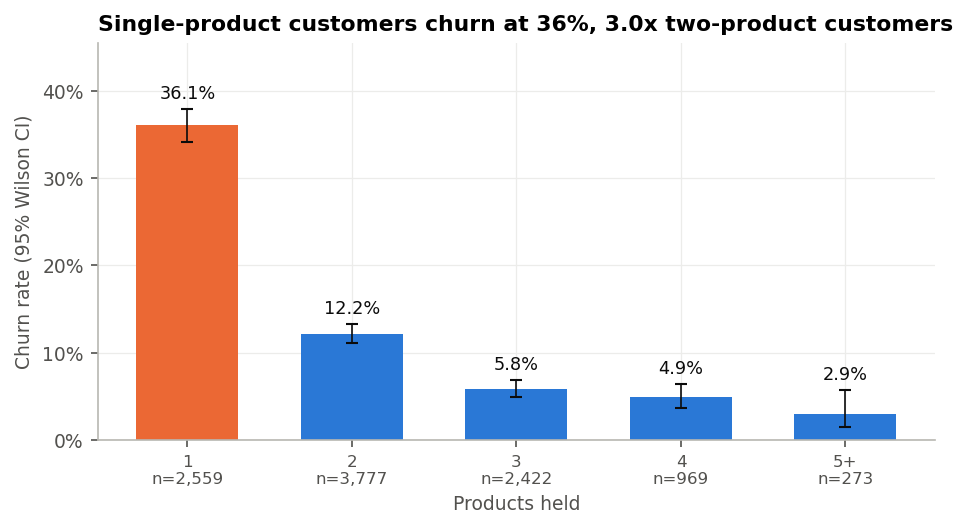

In [10]:
display(Image('../outputs/figures/04_products_vs_churn.png'))

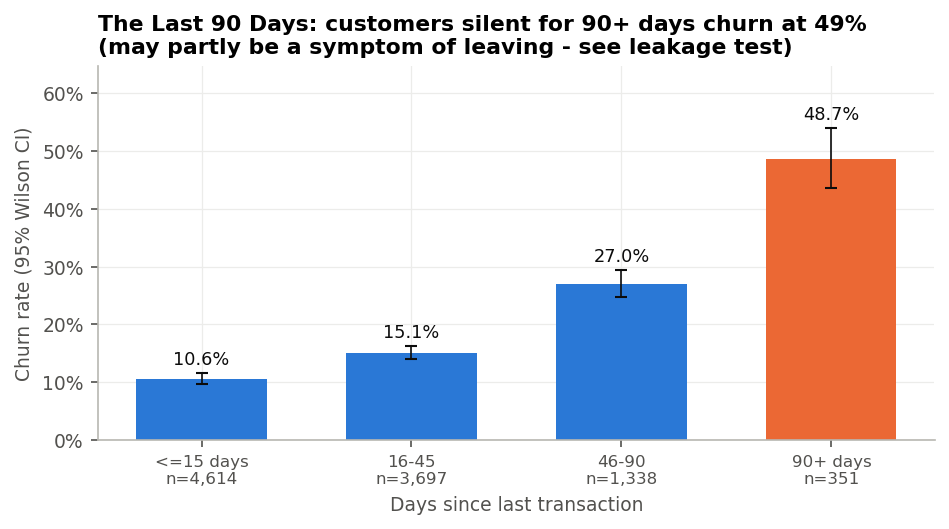

In [11]:
display(Image('../outputs/figures/05_inactivity_silent_exits.png'))

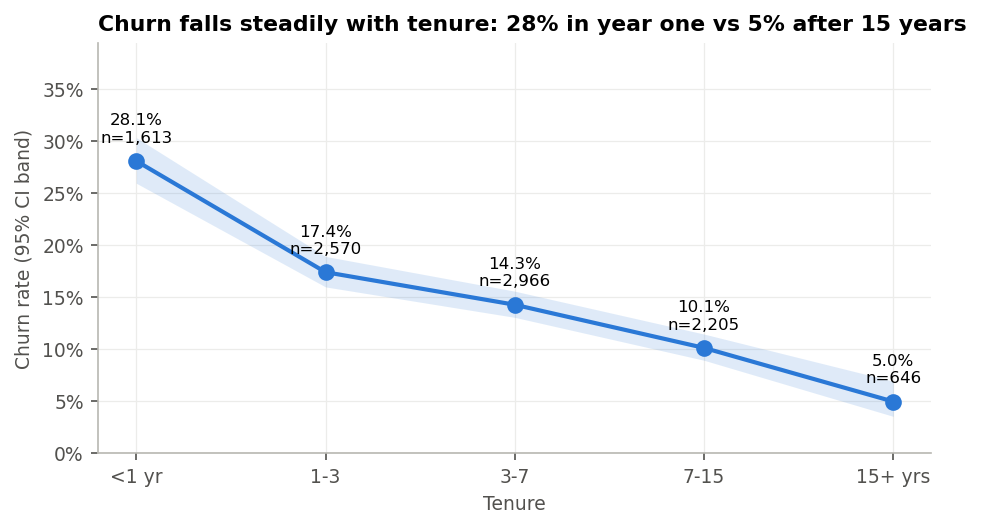

In [12]:
display(Image('../outputs/figures/06_tenure_curve.png'))

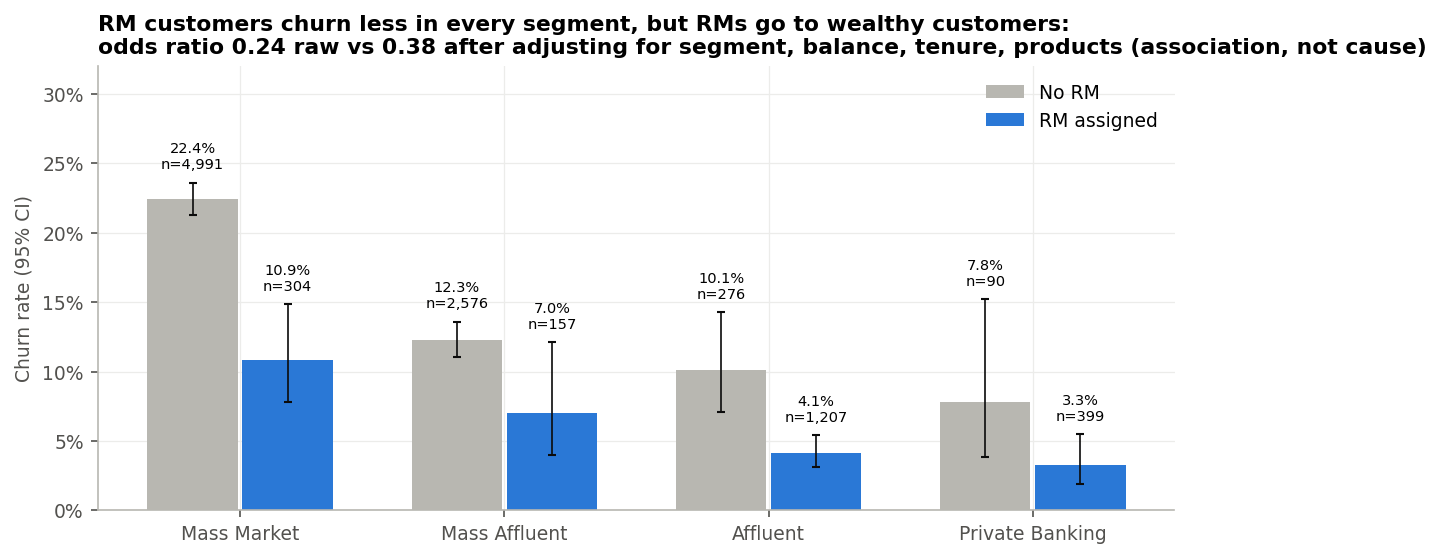

In [13]:
display(Image('../outputs/figures/07_rm_confounding_by_segment.png'))

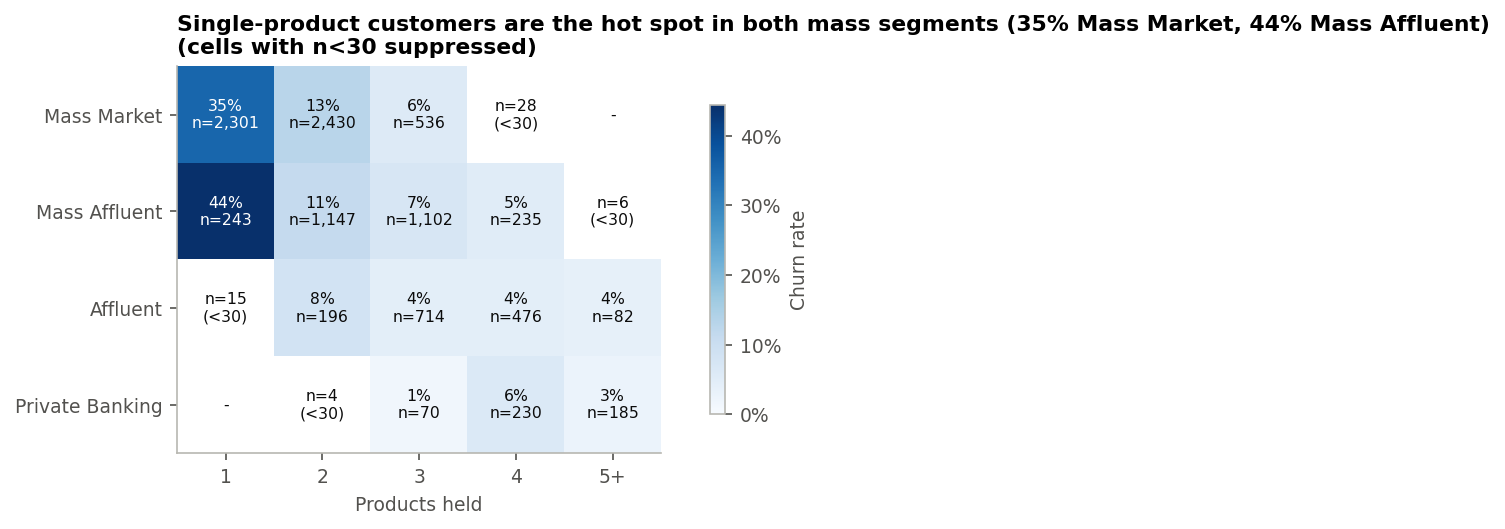

In [14]:
display(Image('../outputs/figures/08_heatmap_segment_x_products.png'))

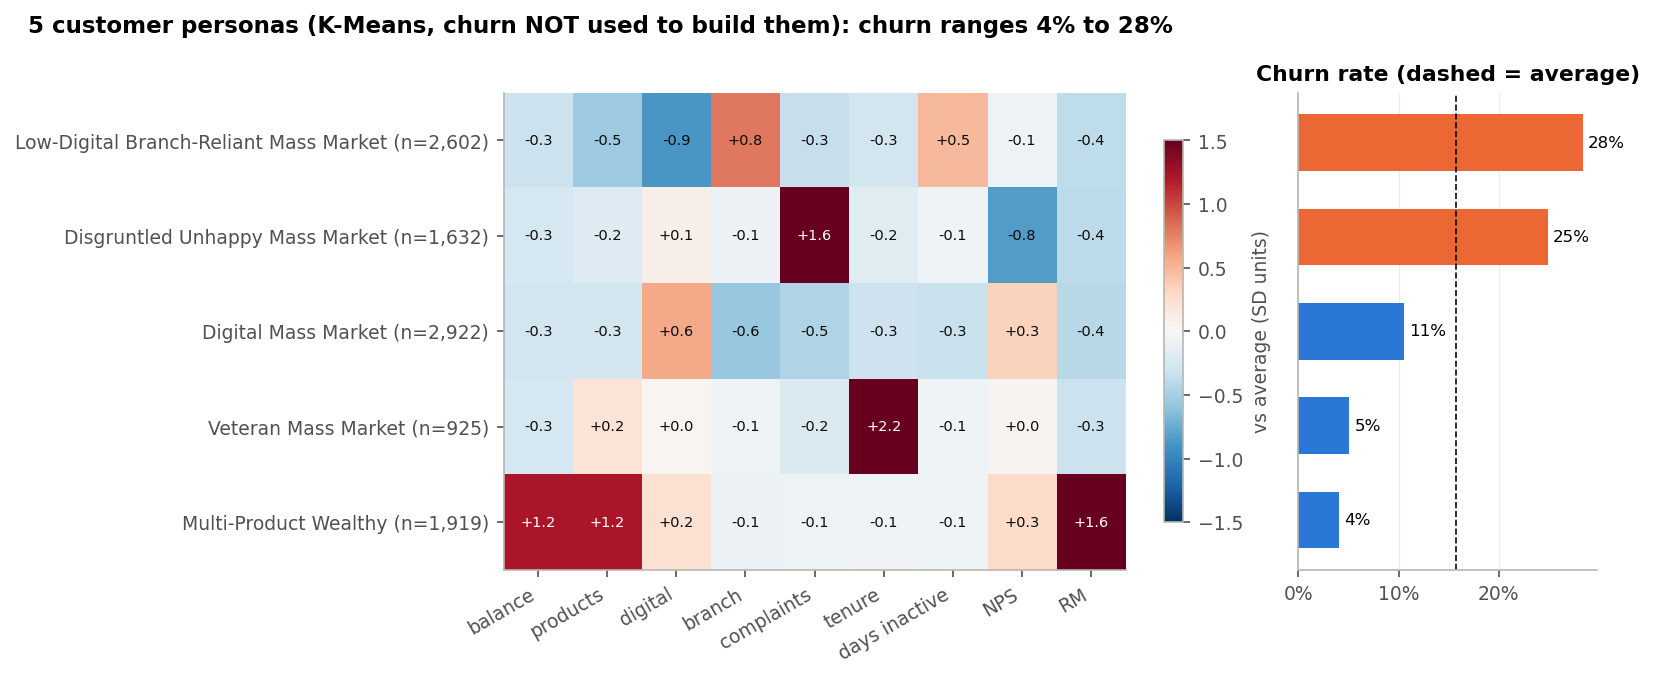

In [15]:
display(Image('../outputs/figures/09_cluster_personas.png'))

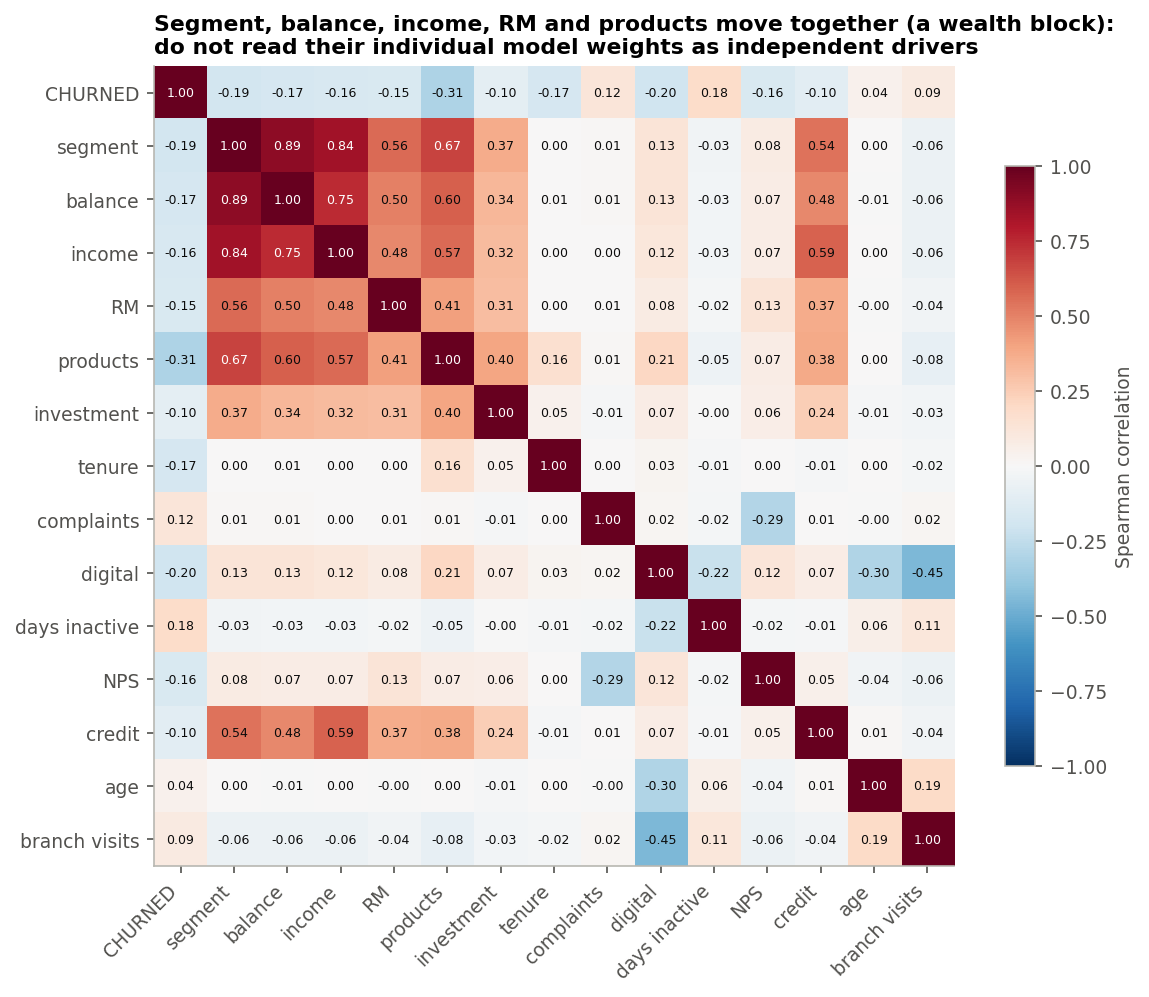

In [16]:
display(Image('../outputs/figures/10_correlation_matrix.png'))